In [1]:
import os # Configure which GPU

if os.getenv("CUDA_VISIBLE_DEVICES") is None:
    gpu_num = 0 # Use "" to use the CPU
    os.environ["CUDA_VISIBLE_DEVICES"] = f"{gpu_num}"
    os.environ["CUDA_VISIBLE_DEVICES"] = "2"
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

# Import Sionna
try:
    import sionna
except ImportError as e:
    # Install Sionna if package is not already installed
    import os
    os.system("pip install sionna")
    import sionna

# Configure the notebook to use only a single GPU and allocate only as much memory as needed
# For more details, see https://www.tensorflow.org/guide/gpu
import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
    except RuntimeError as e:
        print(e)
# Avoid warnings from TensorFlow
tf.get_logger().setLevel('ERROR')

# Colab does currently not support the latest version of ipython.
# Thus, the preview does not work in Colab. However, whenever possible we
# strongly recommend to use the scene preview mode.
try: # detect if the notebook runs in Colab
    import google.colab
    no_preview = True # deactivate preview
except:
    if os.getenv("SIONNA_NO_PREVIEW"):
        no_preview = True
    else:
        no_preview = False

resolution = [480,320] # increase for higher quality of renderings

# Define magic cell command to skip a cell if needed
from IPython.core.magic import register_cell_magic
from IPython import get_ipython

@register_cell_magic
def skip_if(line, cell):
    if eval(line):
        return
    get_ipython().run_cell(cell)

# Set random seed for reproducibility
sionna.config.seed = 42

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import time

# Import Sionna RT components
from sionna.rt import load_scene, Transmitter, Receiver, PlanarArray, Camera

# For link-level simulations
from sionna.channel import cir_to_ofdm_channel, subcarrier_frequencies, OFDMChannel, ApplyOFDMChannel, CIRDataset
from sionna.nr import PUSCHConfig, PUSCHTransmitter, PUSCHReceiver
from sionna.utils import compute_ber, ebnodb2no, PlotBER

# from model import SISOConfig, MIMOConfig, Model, CIRGenerator, PUSCHModel


In [3]:
from sionna.mimo import StreamManagement
from sionna.ofdm import KBestDetector, LinearDetector
from sionna.utils import compute_ber, ebnodb2no
from sionna.nr import PUSCHConfig, PUSCHTransmitter, PUSCHReceiver
from sionna.channel import OFDMChannel, ApplyOFDMChannel
from sionna.channel.tr38901 import CDL, TDL

import tensorflow as tf
import numpy as np
# Import Sionna RT components


class SISOConfig:
    def __init__(self):
        self.num_prb = 16
        self.mcs_index = 14
        self.num_layers = 1
        self.mcs_table = 2  # 256-QAM table
        self.domain = "freq"
        self.num_tx_ant = 1  # Single antenna for SISO
        self.num_tx = 1  # Single transmitter
        self.num_rx_ant = 1
        self.num_rx = 1
        self.subcarrier_spacing = 15e3  # 15 kHz subcarrier spacing
        self.num_symbols = 14  # Full 14 symbols per slot

        # Initialize PUSCHConfig
        self.pusch_config = PUSCHConfig()
        self.pusch_config.carrier.subcarrier_spacing = self.subcarrier_spacing / 1000
        self.pusch_config.carrier.n_size_grid = self.num_prb
        self.pusch_config.num_antenna_ports = self.num_tx_ant
        self.pusch_config.num_layers = self.num_layers
        self.pusch_config.precoding = "non-codebook"
        self.pusch_config.tpmi = 1
        self.pusch_config.dmrs.dmrs_port_set = list(range(self.num_layers))
        self.pusch_config.dmrs.config_type = 1
        self.pusch_config.dmrs.length = 1
        self.pusch_config.dmrs.additional_position = 1
        self.pusch_config.dmrs.num_cdm_groups_without_data = 2
        self.pusch_config.dmrs.positions = [
            2, 11]  # DMRS at positions 2 and 11
        self.pusch_config.tb.mcs_index = self.mcs_index
        self.pusch_config.tb.mcs_table = self.mcs_table

    def create_pusch_configs(self):
        return [self.pusch_config]  # Only one config for SISO


class MIMOConfig:
    def __init__(self):
        self.num_prb = 16
        self.mcs_index = 14
        self.num_layers = 1
        self.mcs_table = 1
        self.domain = "freq"
        self.num_tx_ant = 4
        self.num_tx = 4
        self.subcarrier_spacing = 30e3
        # Initialize pusch_config here
        self.pusch_config = PUSCHConfig()
        self.pusch_config.carrier.subcarrier_spacing = self.subcarrier_spacing / 1000
        self.pusch_config.carrier.n_size_grid = self.num_prb
        self.pusch_config.num_antenna_ports = self.num_tx_ant
        self.pusch_config.num_layers = self.num_layers
        self.pusch_config.precoding = "codebook"
        self.pusch_config.tpmi = 1
        self.pusch_config.dmrs.dmrs_port_set = list(range(self.num_layers))
        self.pusch_config.dmrs.config_type = 1
        self.pusch_config.dmrs.length = 1
        self.pusch_config.dmrs.additional_position = 1
        self.pusch_config.dmrs.num_cdm_groups_without_data = 2
        self.pusch_config.tb.mcs_index = self.mcs_index
        self.pusch_config.tb.mcs_table = self.mcs_table

    def create_pusch_configs(self):
        pusch_configs = [self.pusch_config]  # Start with the base config
        for i in range(1, self.num_tx):
            pc = self.pusch_config.clone()  # Clone for each transmitter
            pc.dmrs.dmrs_port_set = list(
                range(i * self.num_layers, (i + 1) * self.num_layers))
            pusch_configs.append(pc)
        return pusch_configs

    # Function for printing the config values
    def print_config(self):
        print(f"Number of PRBs: {self.num_prb}")
        print(f"MCS index: {self.mcs_index}")
        print(f"Number of layers: {self.num_layers}")
        print(f"Number of antennas: {self.num_tx_ant}")
        print(f"Subcarrier spacing: {self.subcarrier_spacing}")
        print(f"Number of transmitters: {self.num_tx}")

class PUSCHReceiverExtension:
    def __init__(self, config, detector, perfect_csi, transmitter):  # Add transmitter as argument
        self.config = config
        self.perfect_csi = perfect_csi
        rx_tx_association = np.ones([1, config.num_tx], bool)
        stream_management = StreamManagement(
            rx_tx_association, config.num_layers)

        assert detector in [None, "lmmse",
                            "kbest"], "Unsupported MIMO detector"
        if detector == None:
            self.detector = None
        elif detector == "lmmse":
            self.detector = LinearDetector(equalizer="lmmse",
                                           output="bit",
                                           demapping_method="maxlog",
                                           resource_grid=transmitter.pusch_transmitter.resource_grid,  # Use transmitter here
                                           stream_management=stream_management,
                                           constellation_type="qam",
                                           num_bits_per_symbol=config.create_pusch_configs()[0].tb.num_bits_per_symbol)
        elif detector == "kbest":
            self.detector = KBestDetector(output="bit",
                                          num_streams=config.num_tx * config.num_layers,
                                          k=64,
                                          resource_grid=transmitter.pusch_transmitter.resource_grid,  # Use transmitter here
                                          stream_management=stream_management,
                                          constellation_type="qam",
                                          num_bits_per_symbol=config.create_pusch_configs()[0].tb.num_bits_per_symbol)

        if self.perfect_csi:
            self.pusch_receiver = PUSCHReceiver(transmitter.pusch_transmitter,  # Use transmitter here
                                                mimo_detector=self.detector,
                                                input_domain=config.domain,
                                                channel_estimator="perfect")
        else:
            self.pusch_receiver = PUSCHReceiver(transmitter.pusch_transmitter,  # Use transmitter here
                                                mimo_detector=self.detector,
                                                input_domain=config.domain)


class Channel:
    def __init__(self, config,
                 channel_model,
                 model_type="",
                 scenario="",
                 ):
        # Access pusch_config from config, but get resource_grid from transmitter
        # because PUSCHConfig does not have this attribute directly
        resource_grid = PUSCHTransmitterExtension(
            config).pusch_transmitter.resource_grid

        if model_type.lower() == "cdl":
            channel_model = CDL(model=scenario.lower(),
                                     num_rx_ant=config.num_rx_ant,
                                     num_tx_ant=config.num_tx_ant,
                                     delay_spread=300e-9,
                                     carrier_frequency=3.5e9,
                                     )
        elif model_type.lower() == "tdl":
            channel_model = TDL(model=scenario.lower(),
                                     num_rx_ant=config.num_rx_ant,
                                     num_tx_ant=config.num_tx_ant,
                                     delay_spread=300e-9,
                                     carrier_frequency=3.5e9,
                                     )
        self.channel = OFDMChannel(
            channel_model,
            resource_grid,
            normalize_channel=True,
            return_channel=True
        )


class CIRGenerator:
    """Creates a generator from a given dataset of channel impulse responses.

    The generator samples ``num_tx`` different transmitters from the given path
    coefficients `a` and path delays `tau` and stacks the CIRs into a single tensor.

    Note that the generator internally samples ``num_tx`` random transmitters
    from the dataset. For this, the inputs ``a`` and ``tau`` must be given for
    a single transmitter (i.e., ``num_tx`` =1) which will then be stacked
    internally.

    Parameters
    ----------
    a : [batch size, num_rx, num_rx_ant, 1, num_tx_ant, num_paths, num_time_steps], complex
        Path coefficients per transmitter.

    tau : [batch size, num_rx, 1, num_paths], float
        Path delays [s] per transmitter.

    num_tx : int
        Number of transmitters

    Output
    -------
    a : [batch size, num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, num_time_steps], tf.complex
        Path coefficients

    tau : [batch size, num_rx, num_tx, num_paths], tf.float
        Path delays [s]
    """

    def __init__(self,
                 a,
                 tau,
                 num_tx):

        # Copy to tensorflow
        self._a = tf.constant(a, tf.complex64)
        self._tau = tf.constant(tau, tf.float32)
        self._dataset_size = self._a.shape[0]

        self._num_tx = num_tx

    def __call__(self):

        # Generator implements an infinite loop that yields new random samples
        while True:
            # Sample 4 random users and stack them together
            idx, _, _ = tf.random.uniform_candidate_sampler(
                tf.expand_dims(
                    tf.range(self._dataset_size, dtype=tf.int64), axis=0),
                num_true=self._dataset_size,
                num_sampled=self._num_tx,
                unique=True,
                range_max=self._dataset_size)

            a = tf.gather(self._a, idx)
            tau = tf.gather(self._tau, idx)

            # Transpose to remove batch dimension
            a = tf.transpose(a, (3, 1, 2, 0, 4, 5, 6))
            tau = tf.transpose(tau, (2, 1, 0, 3))

            # And remove batch-dimension
            a = tf.squeeze(a, axis=0)
            tau = tf.squeeze(tau, axis=0)

            yield a, tau


class PUSCHTransmitterExtension:
    def __init__(self, config):
        self.config = config
        self.pusch_transmitter = PUSCHTransmitter(
            config.create_pusch_configs(), output_domain=config.domain)


class ChannelModel:
    def __init__(self, cir_generator, batch_size, num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, num_time_steps):
        self.cir_generator = cir_generator
        self.batch_size = batch_size
        self.num_rx = num_rx
        self.num_rx_ant = num_rx_ant
        self.num_tx = num_tx
        self.num_tx_ant = num_tx_ant
        self.num_paths = num_paths
        self.num_time_steps = num_time_steps

    # def __call__(self):
    def __call__(self):
        return self.cir_generator()

    def __len__(self):
        return self.batch_size


class PUSCHModel(tf.keras.Model):
    def __init__(self, h_freq, ebno_db=2.0, batch_size=100):
        super().__init__()
        self.ebno_db = ebno_db
        self.batch_size = batch_size
        self.h_freq = h_freq  # Store h_freq as attribute
        # Simplified PUSCHConfig
        self.pusch_config = PUSCHConfig()
        self.pusch_transmitter = PUSCHTransmitter(self.pusch_config)
        self.pusch_receiver = PUSCHReceiver(self.pusch_transmitter)
        self.no = self.compute_noise()
        self.channel = ApplyOFDMChannel(add_awgn=True)

    def compute_noise(self):
        return ebnodb2no(self.ebno_db,
                         self.pusch_transmitter._num_bits_per_symbol,
                         self.pusch_transmitter._target_coderate,
                         self.pusch_transmitter.resource_grid)

    @tf.function(jit_compile=False)
    def call(self, batch_size, ebno_db):
        x, b = self.pusch_transmitter(batch_size)
        y = self.channel([x, self.h_freq, self.no])
        b_hat = self.pusch_receiver([y, self.no])
        return b, b_hat

    def run(self):
        b, b_hat = self.call(self.batch_size, self.ebno_db)
        ber = compute_ber(b, b_hat).numpy()
        print(f"BER: {ber:.5f}")

class Model(tf.keras.Model):
    def __init__(self,
                 channel_model,
                 perfect_csi,
                 detector,
                 config,
                 model_type="",
                 scenario="",
                 ):
        super().__init__()
        self.config = config
        self.transmitter = PUSCHTransmitterExtension(self.config)
        self.receiver = PUSCHReceiverExtension(
            self.config, detector, perfect_csi, self.transmitter)
        self.channel = Channel(
            self.config,
            channel_model,
            model_type,
            scenario,
        )

    @tf.function(jit_compile=False)
    def call(self, batch_size, ebno_db):
        x, b = self.transmitter.pusch_transmitter(batch_size)
        no = ebnodb2no(ebno_db,
                       self.transmitter.pusch_transmitter._num_bits_per_symbol,
                       self.transmitter.pusch_transmitter._target_coderate,
                       self.transmitter.pusch_transmitter.resource_grid)
        # Print the config for precheck


        print(x.shape())
        print(no.shape())
        y, h = self.channel.channel([x, no])
        if self.receiver.perfect_csi:
            b_hat = self.receiver.pusch_receiver([y, h, no])
        else:
            b_hat = self.receiver.pusch_receiver([y, no])
        return b, b_hat

    def run(self, batch_size, ebno_db):
        b, b_hat = self.call(batch_size, ebno_db)
        ber = compute_ber(b, b_hat).numpy()
        print(f"BER: {ber:.5f}")

    def extract_features(self, batch_size, ebno_db):
        x, b = self.transmitter.pusch_transmitter(batch_size)
        no = ebnodb2no(ebno_db,
                       self.transmitter.pusch_transmitter._num_bits_per_symbol,
                       self.transmitter.pusch_transmitter._target_coderate,
                       self.transmitter.pusch_transmitter.resource_grid)
        y, h = self.channel.channel([x, no])

        features = self.compute_features(y, h, no)
        return features

    def compute_features(self, y, h, no):
        # First, compute the received signal-to-noise ratio
        snr = tf.reduce_sum(tf.abs(y)**2, axis=(1, 2)) / \
            tf.reduce_sum(tf.abs(no)**2, axis=(1, 2))

        # Compute the channel capacity
        capacity = tf.math.log2(1 + snr)

        return capacity


In [4]:
# Load integrated scene
scene = load_scene(sionna.rt.scene.munich) # Try also sionna.rt.scene.etoile

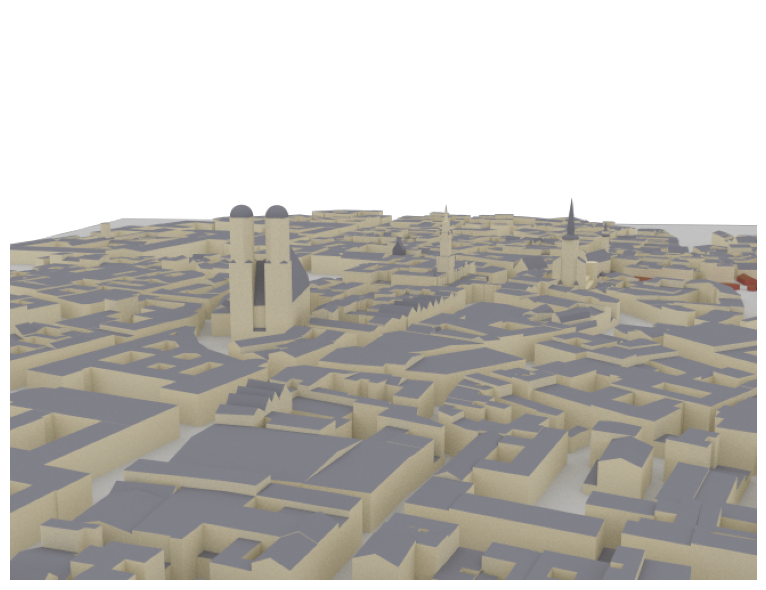

In [5]:
# Render scene
if no_preview:
    scene.render(camera="scene-cam-0", num_samples=512);

# The preview camera can be directly rendered as high-quality image (option only available in local mode)
if not no_preview:
    scene.preview()
    scene.render(camera="preview", num_samples=512);
else:
    print("Function not available in Colab mode.")

In [6]:
%%skip_if no_preview
# Open 3D preview (only works in Jupyter notebook)
scene.preview()

Renderer(camera=PerspectiveCamera(aspect=1.31, children=(DirectionalLight(intensity=0.25, matrixWorldNeedsUpda…

One can also render the image to a file as shown below:

In [7]:
render_to_file = False # Set to True to render image to file

# Render scene to file from preview viewpoint
if render_to_file:
    scene.render_to_file(camera="scene-cam-0", # Also try camera="preview"
                         filename="scene.png",
                         resolution=[650,500])

Instead of the preview camera, one can also specify dedicated cameras with different positions and `look_at` directions.

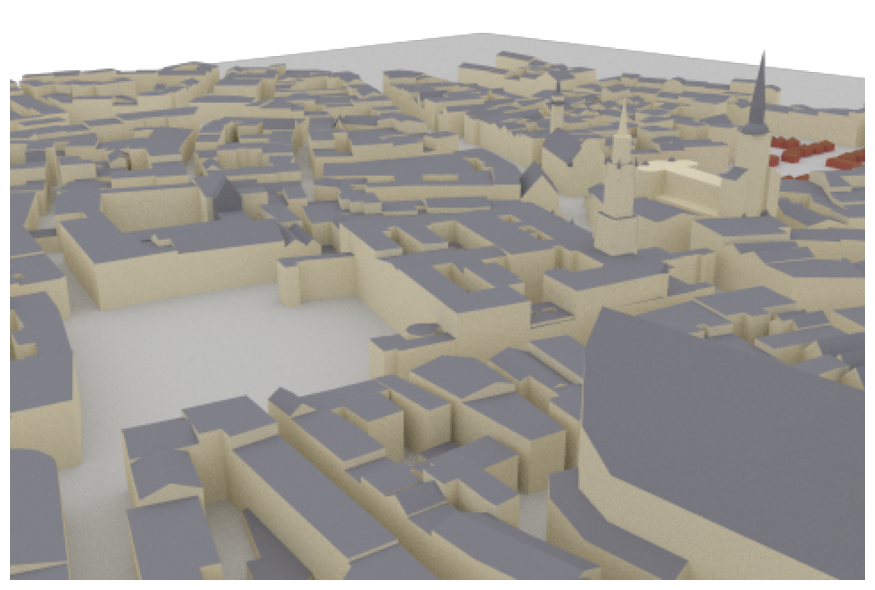

In [8]:
# Create new camera with different configuration
my_cam = Camera("my_cam", position=[-250,250,150], look_at=[-15,30,28])
scene.add(my_cam)

# Render scene with new camera*
scene.render("my_cam", resolution=resolution, num_samples=512); # Increase num_samples to increase image quality

In [9]:
# Configure antenna array for all transmitters
scene.tx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="tr38901",
                             polarization="V")

# Configure antenna array for all receivers
scene.rx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="dipole",
                             polarization="cross")

# Create transmitter
tx = Transmitter(name="tx",
                 position=[8.5,21,27])

# Add transmitter instance to scene
scene.add(tx)

# Create a receiver
rx = Receiver(name="rx",
              position=[45,90,1.5],
              orientation=[0,0,0])

# Add receiver instance to scene
scene.add(rx)

tx.look_at(rx) # Transmitter points towards receiver

In [10]:
scene.frequency = 2.14e9 # in Hz; implicitly updates RadioMaterials

scene.synthetic_array = True # If set to False, ray tracing will be done per antenna element (slower for large arrays)

The default scenes have RadioMaterials assigned to each scene object. However, the RadioMaterial of a specific object can be modified and customized by the user.

In [11]:
# Select an example object from the scene
so = scene.get("Altes_Rathaus-itu_marble")

# Print name of assigned radio material for different frequenies
for f in [3.5e9, 2.14e9]: # Print for differrent frequencies
    scene.frequency = f
    print(f"\nRadioMaterial: {so.radio_material.name} @ {scene.frequency/1e9:.2f}GHz")
    print("Conductivity:", so.radio_material.conductivity.numpy())
    print("Relative permittivity:", so.radio_material.relative_permittivity.numpy())
    print("Complex relative permittivity:", so.radio_material.complex_relative_permittivity.numpy())
    print("Relative permeability:", so.radio_material.relative_permeability.numpy())
    print("Scattering coefficient:", so.radio_material.scattering_coefficient.numpy())
    print("XPD coefficient:", so.radio_material.xpd_coefficient.numpy())


RadioMaterial: itu_marble @ 3.50GHz
Conductivity: 0.017550057
Relative permittivity: 7.074
Complex relative permittivity: (7.074-0.090132594j)
Relative permeability: 1.0
Scattering coefficient: 0.0
XPD coefficient: 0.0

RadioMaterial: itu_marble @ 2.14GHz
Conductivity: 0.0111273555
Relative permittivity: 7.074
Complex relative permittivity: (7.074-0.09346512j)
Relative permeability: 1.0
Scattering coefficient: 0.0
XPD coefficient: 0.0


In [12]:
# Compute propagation paths
paths = scene.compute_paths(max_depth=5,
                            num_samples=5e4)  # Number of rays shot into directions defined
                                              # by a Fibonacci sphere , too few rays can
                                              # lead to missing paths

# Visualize paths in the scene
if no_preview:
    scene.render("my_cam", paths=paths, show_devices=True, show_paths=True, resolution=resolution);

In [13]:
%%skip_if no_preview
scene.preview(paths, show_devices=True, show_paths=True) # Use the mouse to focus on the visualized paths

Renderer(camera=PerspectiveCamera(aspect=1.31, children=(DirectionalLight(intensity=0.25, matrixWorldNeedsUpda…

In [14]:
# Show the coordinates of the starting points of all rays.
# These coincide with the location of the transmitters.
print("Source coordinates: ", paths.sources.numpy())
print("Transmitter coordinates: ", list(scene.transmitters.values())[0].position.numpy())

# Show the coordinates of the endpoints of all rays.
# These coincide with the location of the receivers.
print("Target coordinates: ",paths.targets.numpy())
print("Receiver coordinates: ",list(scene.receivers.values())[0].position.numpy())

# Show the types of all paths:
# 0 - LoS, 1 - Reflected, 2 - Diffracted, 3 - Scattered
# Note that Diffraction and scattering are turned off by default.
print("Path types: ", paths.types.numpy())

Source coordinates:  [[ 8.5 21.  27. ]]
Transmitter coordinates:  [ 8.5 21.  27. ]
Target coordinates:  [[45.  90.   1.5]]
Receiver coordinates:  [45.  90.   1.5]
Path types:  [[0 1 1 1 1 1 1 1 1 1 1 1]]


In [15]:
# We can now access for every path the channel coefficient, the propagation delay,
# as well as the angles of departure and arrival, respectively (zenith and azimuth).

# Let us inspect a specific path in detail
path_idx = 4 # Try out other values in the range [0, 13]

# For a detailed overview of the dimensions of all properties, have a look at the API documentation
print(f"\n--- Detailed results for path {path_idx} ---")
print(f"Channel coefficient: {paths.a[0,0,0,0,0,path_idx, 0].numpy()}")
print(f"Propagation delay: {paths.tau[0,0,0,path_idx].numpy()*1e6:.5f} us")
print(f"Zenith angle of departure: {paths.theta_t[0,0,0,path_idx]:.4f} rad")
print(f"Azimuth angle of departure: {paths.phi_t[0,0,0,path_idx]:.4f} rad")
print(f"Zenith angle of arrival: {paths.theta_r[0,0,0,path_idx]:.4f} rad")
print(f"Azimuth angle of arrival: {paths.phi_r[0,0,0,path_idx]:.4f} rad")


--- Detailed results for path 4 ---
Channel coefficient: (-9.857268196356017e-06-1.1824702284002342e-07j)
Propagation delay: 0.75675 us
Zenith angle of departure: 1.6632 rad
Azimuth angle of departure: 1.2045 rad
Zenith angle of arrival: 1.6632 rad
Azimuth angle of arrival: -1.9260 rad


In [16]:
# Default parameters in the PUSCHConfig
subcarrier_spacing = 15e3
fft_size = 48

Doppler Effect

In [17]:
# Print shape of channel coefficients before the application of Doppler shifts
# The last dimension corresponds to the number of time steps which defaults to one
# as there is no mobility
print("Shape of `a` before applying Doppler shifts: ", paths.a.shape)

# Apply Doppler shifts
paths.apply_doppler(sampling_frequency=subcarrier_spacing, # Set to 15e3 Hz
                    num_time_steps=14, # Number of OFDM symbols
                    tx_velocities=[3.,0,0], # We can set additional tx speeds
                    rx_velocities=[0,7.,0]) # Or rx speeds

print("Shape of `a` after applying Doppler shifts: ", paths.a.shape)

a, tau = paths.cir()
print("Shape of tau: ", tau.shape)

Shape of `a` before applying Doppler shifts:  (1, 1, 2, 1, 1, 12, 1)
Shape of `a` after applying Doppler shifts:  (1, 1, 2, 1, 1, 12, 14)
Shape of tau:  (1, 1, 1, 12)


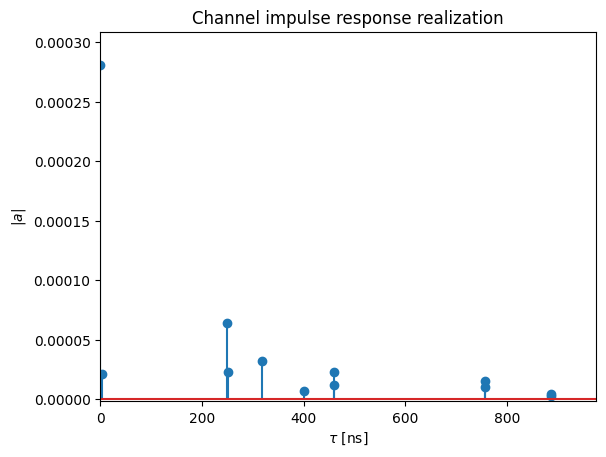

In [18]:
t = tau[0,0,0,:]/1e-9 # Scale to ns
a_abs = np.abs(a)[0,0,0,0,0,:,0]
a_max = np.max(a_abs)
# Add dummy entry at start/end for nicer figure
t = np.concatenate([(0.,), t, (np.max(t)*1.1,)])
a_abs = np.concatenate([(np.nan,), a_abs, (np.nan,)])

# And plot the CIR
plt.figure()
plt.title("Channel impulse response realization")

plt.stem(t, a_abs)
plt.xlim([0, np.max(t)])
plt.ylim([-2e-6, a_max*1.1])
plt.xlabel(r"$\tau$ [ns]")
plt.ylabel(r"$|a|$");

In [19]:
# Disable normalization of delays
paths.normalize_delays = False

# Get only the LoS path
_, tau = paths.cir(los=True, reflection=False)
print("Delay of first path without normalization: ", np.squeeze(tau))

paths.normalize_delays = True
_, tau = paths.cir(los=True, reflection=False)
print("Delay of first path with normalization: ", np.squeeze(tau))

Delay of first path without normalization:  2.739189e-07
Delay of first path with normalization:  0.0


In [20]:
# Compute frequencies of subcarriers and center around carrier frequency
frequencies = subcarrier_frequencies(fft_size, subcarrier_spacing)

# Compute the frequency response of the channel at frequencies.
h_freq = cir_to_ofdm_channel(frequencies,
                             a,
                             tau,
                             normalize=True) # Non-normalized includes path-loss

# Verify that the channel power is normalized
h_avg_power = tf.reduce_mean(tf.abs(h_freq)**2).numpy()

print("Shape of h_freq: ", h_freq.shape)
print("Average power h_freq: ", h_avg_power) # Channel is normalized

Shape of h_freq:  (1, 1, 2, 1, 1, 14, 48)
Average power h_freq:  1.0


5G PUSCH Part

In [21]:
# Placeholder for tx signal of shape
# [batch size, num_tx, num_tx_ant, num_ofdm_symbols, fft_size]
x = tf.zeros([h_freq.shape.as_list()[i] for i in [0,3,4,5,6]], tf.complex64)

no = 0.1 # noise variance

# Init channel layer
channel = ApplyOFDMChannel(add_awgn=True)

# Apply channel
y = channel([x, h_freq, no])

# [batch size, num_rx, num_rx_ant, num_ofdm_symbols, fft_size]
print(y.shape)

(1, 1, 2, 14, 48)


In [22]:
# Init pusch_transmitter
pusch_config = PUSCHConfig()

# Instantiate a PUSCHTransmitter from the PUSCHConfig
pusch_transmitter = PUSCHTransmitter(pusch_config)

# Create a PUSCHReceiver using the PUSCHTransmitter
pusch_receiver = PUSCHReceiver(pusch_transmitter)
# Simulate transmissions over the
batch_size = 100 # h_freq is broadcast, i.e., same CIR for all samples but different AWGN realizations
ebno_db = 2. # SNR in dB

no = ebnodb2no(ebno_db,
               pusch_transmitter._num_bits_per_symbol,
               pusch_transmitter._target_coderate,
               pusch_transmitter.resource_grid)

x, b = pusch_transmitter(batch_size) # Generate transmit signal and info bits

y = channel([x, h_freq, no]) # Simulate channel output

b_hat = pusch_receiver([y, no]) # Recover the info bits

# Compute BER
print(f"BER: {compute_ber(b, b_hat).numpy():.5f}")

BER: 0.07305


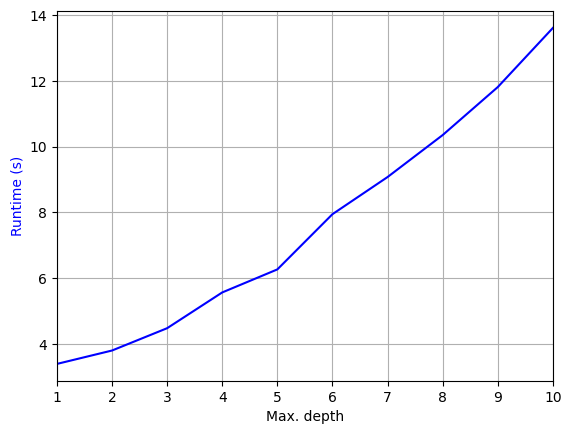

In [23]:
max_depths = 10 # evaluate performance up to 10 reflections
depths = range(1,max_depths+1)
ts = []
pl_avg = []
for d in depths:
    # save start time
    t = time.time()
    # run the ray tracer
    paths = scene.compute_paths(max_depth=d)
    # and measure the required time interval
    ts.append(time.time()-t)
# and plot results
plt.figure()
plt.plot(depths, ts, color="b");
plt.xlabel("Max. depth")
plt.ylabel("Runtime (s)", color="b")
plt.grid(which="both")
plt.xlim([1, max_depths]);

In [24]:
t = time.time()
paths = scene.compute_paths(max_depth=3, diffraction=False)
print("Time without diffraction and scattering:" , time.time()-t)

t = time.time()
paths = scene.compute_paths(max_depth=3, diffraction=True)
print("Time with diffraction:" , time.time()-t)

t = time.time()
paths = scene.compute_paths(max_depth=3, scattering=True)
print("Time with scattering:" , time.time()-t)

Time without diffraction and scattering: 4.376624584197998
Time with diffraction: 6.207971572875977
Time with scattering: 5.614094018936157


In [25]:
# Remove old transmitter and add new one
scene.remove("tx")

tx = Transmitter(name="tx",
                 position=[-210,73,105], # top of Frauenkirche
                 orientation=[0,0,0])
scene.add(tx)

# We could have alternatively modified the properties position and orientation of the existing transmitter
#scene.get("tx").position = [-210,73,105]
#scene.get("tx").orientation = [0,0,0]

In [26]:
 # Open 3D preview (only works in Jupyter notebook)
if no_preview:
    scene.render(camera="scene-cam-0", num_samples=512, resolution=resolution);

In [27]:
%%skip_if no_preview
scene.preview()

Renderer(camera=PerspectiveCamera(aspect=1.31, children=(DirectionalLight(intensity=0.25, matrixWorldNeedsUpda…

In [28]:
cm = scene.coverage_map(max_depth=5,
                        diffraction=True, # Disable to see the effects of diffraction
                        cm_cell_size=(5., 5.), # Grid size of coverage map cells in m
                        combining_vec=None,
                        precoding_vec=None,
                        num_samples=int(5e4)) # Reduce if your hardware does not have enough memory

In [29]:
# Create new camera
tx_pos = scene.transmitters["tx"].position.numpy()
bird_pos = tx_pos.copy()
bird_pos[-1] = 1000 # Set height of coverage map to 1000m above tx
bird_pos[-2]-= 0.01 # Slightly move the camera for correct orientation

# Create new camera
bird_cam = Camera("birds_view", position=bird_pos, look_at=tx_pos)

scene.add(bird_cam)

if no_preview:
    scene.render(camera="birds_view", coverage_map=cm, num_samples=512, resolution=resolution);

In [30]:
%%skip_if no_preview
scene.preview(coverage_map=cm)

Renderer(camera=PerspectiveCamera(aspect=1.31, children=(DirectionalLight(intensity=0.25, matrixWorldNeedsUpda…

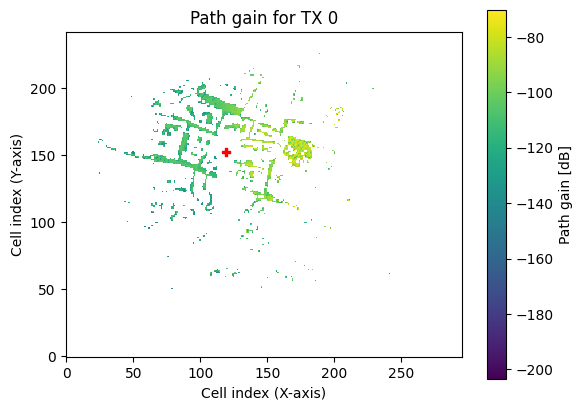

In [31]:
cm.show(tx=0); # If multiple transmitters exist, tx selects for which transmitter the cm is shown

In [32]:
# System parameters
subcarrier_spacing = 30e3
num_time_steps = 14 # Total number of ofdm symbols per slot

num_tx = 4 # Number of users
num_rx = 1 # Only one receiver considered
num_tx_ant = 4 # Each user has 4 antennas
num_rx_ant = 16 # The receiver is equipped with 16 antennas

# batch_size for CIR generation
batch_size_cir = 500

In [33]:
# Remove old tx from scene
scene.remove("tx")

scene.synthetic_array = True # Emulate multiple antennas to reduce ray tracing complexity

# Transmitter (=basestation) has an antenna pattern from 3GPP 38.901
scene.tx_array = PlanarArray(num_rows=1,
                             num_cols=int(num_rx_ant/2), # We want to transmitter to be equiped with the 16 rx antennas
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="tr38901",
                             polarization="cross")

# Create transmitter
tx = Transmitter(name="tx",
                 position=[8.5,21,27],
                 look_at=[45,90,1.5]) # optional, defines view direction
scene.add(tx)
max_depth = 5 # Defines max number of ray interactions

# Update coverage_map
cm = scene.coverage_map(max_depth=max_depth,
                        diffraction=True,
                        cm_cell_size=(1., 1.),
                        combining_vec=None,
                        precoding_vec=None,
                        num_samples=int(5e4))

In [34]:
min_gain_db = -130 # in dB; ignore any position with less than -130 dB path gain
max_gain_db = 0 # in dB; ignore strong paths

# sample points in a 5-400m radius around the receiver
min_dist = 5 # in m
max_dist = 400 # in m

#sample batch_size random user positions from coverage map
ue_pos, _ = cm.sample_positions(num_pos=batch_size_cir,
                                metric="path_gain",
                                min_val_db=min_gain_db,
                                max_val_db=max_gain_db,
                                min_dist=min_dist,
                                max_dist=max_dist)
ue_pos = tf.squeeze(ue_pos)

In [35]:
# Remove old receivers from scene
scene.remove("rx")
for i in range(batch_size_cir):
    scene.remove(f"rx-{i}")

# Configure antenna array for all receivers (=UEs)
scene.rx_array = PlanarArray(num_rows=1,
                             num_cols=int(num_tx_ant/2), # Each receiver is equipped with 4 tx antennas (uplink)
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="iso", # UE orientation is random
                             polarization="cross")

# Create batch_size receivers
for i in range(batch_size_cir):
    rx = Receiver(name=f"rx-{i}",
                  position=ue_pos[i], # Random position sampled from coverage map
                  )
    scene.add(rx)

# And visualize the scene
if no_preview:
    scene.render("birds_view", show_devices=True, resolution=resolution);

In [36]:
%%skip_if no_preview
scene.preview(show_devices=True, coverage_map=cm)

Renderer(camera=PerspectiveCamera(aspect=1.31, children=(DirectionalLight(intensity=0.25, matrixWorldNeedsUpda…

In [37]:
target_num_cirs = 2500 # Defines how many different CIRS are generated.
# Remark: some path are removed if no path was found for this position

max_depth = 5
min_gain_db = -130 # in dB / ignore any position with less than -130 dB path gain
max_gain_db = 0 # in dB / ignore any position with more than 0 dB path gain

# Sample points within a 10-400m radius around the transmitter
min_dist = 10 # in m
max_dist = 400 # in m

# Placeholder to gather channel impulse reponses
a = None
tau = None

# Each simulation returns batch_size_cir results
num_runs = int(np.ceil(target_num_cirs/batch_size_cir))
for idx in range(num_runs):
    print(f"Progress: {idx+1}/{num_runs}", end="\r")

    # Sample random user positions
    ue_pos, _ = cm.sample_positions(
                        num_pos=batch_size_cir,
                        metric="path_gain",
                        min_val_db=min_gain_db,
                        max_val_db=max_gain_db,
                        min_dist=min_dist,
                        max_dist=max_dist)
    ue_pos = tf.squeeze(ue_pos)

    # Update all receiver positions
    for idx in range(batch_size_cir):
        scene.receivers[f"rx-{idx}"].position = ue_pos[idx]

    # Simulate CIR
    paths = scene.compute_paths(
                    max_depth=max_depth,
                    diffraction=True,
                    num_samples=5e4) # shared between all tx in a scene

    # Transform paths into channel impulse responses
    paths.reverse_direction = True # Convert to uplink direction
    paths.apply_doppler(sampling_frequency=subcarrier_spacing,
                        num_time_steps=14,
                        tx_velocities=[0.,0.,0],
                        rx_velocities=[3.,3.,0])

    # We fix here the maximum number of paths to 75 which ensures
    # that we can simply concatenate different channel impulse reponses
    a_, tau_ = paths.cir(num_paths=75)
    del paths # Free memory

    if a is None:
        a = a_.numpy()
        tau = tau_.numpy()
    else:
        # Concatenate along the num_tx dimension
        a = np.concatenate([a, a_], axis=3)
        tau = np.concatenate([tau, tau_], axis=2)

del cm # Free memory

# Exchange the num_tx and batchsize dimensions
a = np.transpose(a, [3, 1, 2, 0, 4, 5, 6])
tau = np.transpose(tau, [2, 1, 0, 3])

# Remove CIRs that have no active link (i.e., a is all-zero)
p_link = np.sum(np.abs(a)**2, axis=(1,2,3,4,5,6))
a = a[p_link>0.,...]
tau = tau[p_link>0.,...]

print("Shape of a:", a.shape)
print("Shape of tau: ", tau.shape)

Shape of a: (2485, 1, 16, 1, 4, 75, 14)
Shape of tau:  (2485, 1, 1, 75)


In [38]:
batch_size = 10 # Must be the same for the BER simulations as CIRDataset returns fixed batch_size
paths = scene.compute_paths(max_depth=3, num_samples=batch_size_cir)

# Init CIR generator
cir_generator = CIRGenerator(a,
                             tau,
                             num_tx)
# Initialises a channel model that can be directly used by OFDMChannel layer
channel_model = CIRDataset(cir_generator,
                           batch_size,
                           num_rx,
                           num_rx_ant,
                           num_tx,
                           num_tx_ant,
                           75,
                           num_time_steps)

# Delete to free memory
del a, tau

In [39]:
# Example usage

# Delete previously imported PUSCHModel to avoid potential conflicts
model = PUSCHModel(h_freq, batch_size=100)
model.run()

BER: 0.06988


In [40]:
from sionna.mimo import StreamManagement
from sionna.ofdm import KBestDetector, LinearDetector
from sionna.utils import compute_ber, ebnodb2no
from sionna.nr import PUSCHConfig, PUSCHTransmitter, PUSCHReceiver
from sionna.channel import OFDMChannel, ApplyOFDMChannel
from sionna.channel.tr38901 import CDL, TDL
from sionna.channel.tr38901 import AntennaArray, Antenna
import tensorflow as tf
import numpy as np
# Import Sionna RT components


class SISOConfig:
    def __init__(self):
        self.num_prb = 16
        self.mcs_index = 14
        self.num_layers = 1
        self.mcs_table = 2  # 256-QAM table
        self.domain = "freq"
        self.num_tx_ant = 1  # Single antenna for SISO
        self.num_tx = 1  # Single transmitter
        self.num_rx_ant = 1
        self.num_rx = 1
        self.subcarrier_spacing = 15e3  # 15 kHz subcarrier spacing
        self.num_symbols = 14  # Full 14 symbols per slot

        # Initialize PUSCHConfig
        self.pusch_config = PUSCHConfig()
        self.pusch_config.carrier.subcarrier_spacing = self.subcarrier_spacing / 1000
        self.pusch_config.carrier.n_size_grid = self.num_prb
        self.pusch_config.num_antenna_ports = self.num_tx_ant
        self.pusch_config.num_layers = self.num_layers
        self.pusch_config.precoding = "non-codebook"
        self.pusch_config.tpmi = 1
        self.pusch_config.dmrs.dmrs_port_set = list(range(self.num_layers))
        self.pusch_config.dmrs.config_type = 1
        self.pusch_config.dmrs.length = 1
        self.pusch_config.dmrs.additional_position = 1
        self.pusch_config.dmrs.num_cdm_groups_without_data = 2
        self.pusch_config.dmrs.positions = [
            2, 11]  # DMRS at positions 2 and 11
        self.pusch_config.tb.mcs_index = self.mcs_index
        self.pusch_config.tb.mcs_table = self.mcs_table

    def create_pusch_configs(self):
        return [self.pusch_config]  # Only one config for SISO

    # Function for printing the config values
    def print_config(self):
        print(f"Number of PRBs: {self.num_prb}")
        print(f"MCS index: {self.mcs_index}")
        print(f"Number of layers: {self.num_layers}")
        print(f"Number of antennas: {self.num_tx_ant}")
        print(f"Subcarrier spacing: {self.subcarrier_spacing}")
        print(f"Number of transmitters: {self.num_tx}")

class MIMOConfig:
    def __init__(self):
        self.num_prb = 16
        self.mcs_index = 14
        self.num_layers = 1
        self.mcs_table = 1
        self.domain = "freq"
        self.num_tx_ant = 4
        self.num_tx = 4
        self.subcarrier_spacing = 30e3
        self.num_rx_ant = 16
        self.num_rx = 1
        # Initialize pusch_config here
        self.pusch_config = PUSCHConfig()
        self.pusch_config.carrier.subcarrier_spacing = self.subcarrier_spacing / 1000
        self.pusch_config.carrier.n_size_grid = self.num_prb
        self.pusch_config.num_antenna_ports = self.num_tx_ant
        self.pusch_config.num_layers = self.num_layers
        self.pusch_config.precoding = "codebook"
        self.pusch_config.tpmi = 1
        self.pusch_config.dmrs.dmrs_port_set = list(range(self.num_layers))
        self.pusch_config.dmrs.config_type = 1
        self.pusch_config.dmrs.length = 1
        self.pusch_config.dmrs.additional_position = 1
        self.pusch_config.dmrs.num_cdm_groups_without_data = 2
        self.pusch_config.tb.mcs_index = self.mcs_index
        self.pusch_config.tb.mcs_table = self.mcs_table

    def create_pusch_configs(self):
        pusch_configs = [self.pusch_config]  # Start with the base config
        for i in range(1, self.num_tx):
            pc = self.pusch_config.clone()  # Clone for each transmitter
            pc.dmrs.dmrs_port_set = list(
                range(i * self.num_layers, (i + 1) * self.num_layers))
            pusch_configs.append(pc)
        return pusch_configs

    # Function for printing the config values
    def print_config(self):
        print(f"Number of PRBs: {self.num_prb}")
        print(f"MCS index: {self.mcs_index}")
        print(f"Number of layers: {self.num_layers}")
        print(f"Number of antennas: {self.num_tx_ant}")
        print(f"Subcarrier spacing: {self.subcarrier_spacing}")
        print(f"Number of transmitters: {self.num_tx}")

class PUSCHReceiverExtension:
    def __init__(self, config, detector, perfect_csi, transmitter):  # Add transmitter as argument
        self.config = config
        self.perfect_csi = perfect_csi
        rx_tx_association = np.ones([1, config.num_tx], bool)
        stream_management = StreamManagement(
            rx_tx_association, config.num_layers)

        assert detector in [None, "lmmse",
                            "kbest"], "Unsupported MIMO detector"
        if detector == None:
            self.detector = None
        elif detector == "lmmse":
            self.detector = LinearDetector(equalizer="lmmse",
                                           output="bit",
                                           demapping_method="maxlog",
                                           resource_grid=transmitter.pusch_transmitter.resource_grid,  # Use transmitter here
                                           stream_management=stream_management,
                                           constellation_type="qam",
                                           num_bits_per_symbol=config.create_pusch_configs()[0].tb.num_bits_per_symbol)
        elif detector == "kbest":
            self.detector = KBestDetector(output="bit",
                                          num_streams=config.num_tx * config.num_layers,
                                          k=64,
                                          resource_grid=transmitter.pusch_transmitter.resource_grid,  # Use transmitter here
                                          stream_management=stream_management,
                                          constellation_type="qam",
                                          num_bits_per_symbol=config.create_pusch_configs()[0].tb.num_bits_per_symbol)

        if self.perfect_csi:
            self.pusch_receiver = PUSCHReceiver(transmitter.pusch_transmitter,  # Use transmitter here
                                                mimo_detector=self.detector,
                                                input_domain=config.domain,
                                                channel_estimator="perfect")
        else:
            self.pusch_receiver = PUSCHReceiver(transmitter.pusch_transmitter,  # Use transmitter here
                                                mimo_detector=self.detector,
                                                input_domain=config.domain)


class Channel:
    def __init__(self, config,
                 channel_model,
                 model_type="",
                 scenario="",
                 ):
        # Access pusch_config from config, but get resource_grid from transmitter
        # because PUSCHConfig does not have this attribute directly
        resource_grid = PUSCHTransmitterExtension(
            config).pusch_transmitter.resource_grid

        if model_type.lower() == "cdl":
            carrier_frequency = 2.6e9 # Carrier frequency in Hz.
                            # This is needed here to define the antenna element spacing
            # Provide the missing arguments to PanelArray
            num_ut_ant = 4
            num_bs_ant = 8
            ut_array = AntennaArray(num_rows=1,
                                    num_cols=int(num_ut_ant/2),
                                    polarization="dual",
                                    polarization_type="cross",
                                    antenna_pattern="38.901",
                                    carrier_frequency=carrier_frequency)
            bs_array = AntennaArray(num_rows=1,
                                    num_cols=int(num_bs_ant/2),
                                    polarization="dual",
                                    polarization_type="cross",
                                    antenna_pattern="38.901",
                                    carrier_frequency=carrier_frequency)
            # Initialize the CDL model with the antenna arrays
            channel_model = CDL(model=scenario,
                                 ut_array=ut_array,  # Add ut_array
                                 bs_array=bs_array,  # Add bs_array
                                 delay_spread=300e-9,
                                 carrier_frequency=3.5e9,
                                 direction = "uplink"
                                 )
        elif model_type.lower() == "tdl":
            channel_model = TDL(model=scenario,
                                     num_rx_ant=config.num_rx_ant,
                                     num_tx_ant=config.num_tx_ant,
                                     delay_spread=300e-9,
                                     carrier_frequency=3.5e9,
                                     )

        self.channel = OFDMChannel(
            channel_model,
            resource_grid,
            normalize_channel=True,
            return_channel=True
        )


class CIRGenerator:
    """Creates a generator from a given dataset of channel impulse responses.

    The generator samples ``num_tx`` different transmitters from the given path
    coefficients `a` and path delays `tau` and stacks the CIRs into a single tensor.

    Note that the generator internally samples ``num_tx`` random transmitters
    from the dataset. For this, the inputs ``a`` and ``tau`` must be given for
    a single transmitter (i.e., ``num_tx`` =1) which will then be stacked
    internally.

    Parameters
    ----------
    a : [batch size, num_rx, num_rx_ant, 1, num_tx_ant, num_paths, num_time_steps], complex
        Path coefficients per transmitter.

    tau : [batch size, num_rx, 1, num_paths], float
        Path delays [s] per transmitter.

    num_tx : int
        Number of transmitters

    Output
    -------
    a : [batch size, num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, num_time_steps], tf.complex
        Path coefficients

    tau : [batch size, num_rx, num_tx, num_paths], tf.float
        Path delays [s]
    """

    def __init__(self,
                 a,
                 tau,
                 num_tx):

        # Copy to tensorflow
        self._a = tf.constant(a, tf.complex64)
        self._tau = tf.constant(tau, tf.float32)
        self._dataset_size = self._a.shape[0]

        self._num_tx = num_tx

    def __call__(self):

        # Generator implements an infinite loop that yields new random samples
        while True:
            # Sample 4 random users and stack them together
            idx, _, _ = tf.random.uniform_candidate_sampler(
                tf.expand_dims(
                    tf.range(self._dataset_size, dtype=tf.int64), axis=0),
                num_true=self._dataset_size,
                num_sampled=self._num_tx,
                unique=True,
                range_max=self._dataset_size)

            a = tf.gather(self._a, idx)
            tau = tf.gather(self._tau, idx)

            # Transpose to remove batch dimension
            a = tf.transpose(a, (3, 1, 2, 0, 4, 5, 6))
            tau = tf.transpose(tau, (2, 1, 0, 3))

            # And remove batch-dimension
            a = tf.squeeze(a, axis=0)
            tau = tf.squeeze(tau, axis=0)

            yield a, tau


class PUSCHTransmitterExtension:
    def __init__(self, config):
        self.config = config
        self.pusch_transmitter = PUSCHTransmitter(
            config.create_pusch_configs(), output_domain=config.domain)


class ChannelModel:
    def __init__(self, cir_generator, batch_size, num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, num_time_steps):
        self.cir_generator = cir_generator
        self.batch_size = batch_size
        self.num_rx = num_rx
        self.num_rx_ant = num_rx_ant
        self.num_tx = num_tx
        self.num_tx_ant = num_tx_ant
        self.num_paths = num_paths
        self.num_time_steps = num_time_steps

    # def __call__(self):
    def __call__(self):
        return self.cir_generator()

    def __len__(self):
        return self.batch_size


class PUSCHModel(tf.keras.Model):
    def __init__(self, h_freq, ebno_db=2.0, batch_size=100):
        super().__init__()
        self.ebno_db = ebno_db
        self.batch_size = batch_size
        self.h_freq = h_freq  # Store h_freq as attribute
        # Simplified PUSCHConfig
        self.pusch_config = PUSCHConfig()
        self.pusch_transmitter = PUSCHTransmitter(self.pusch_config)
        self.pusch_receiver = PUSCHReceiver(self.pusch_transmitter)
        self.no = self.compute_noise()
        self.channel = ApplyOFDMChannel(add_awgn=True)

    def compute_noise(self):
        return ebnodb2no(self.ebno_db,
                         self.pusch_transmitter._num_bits_per_symbol,
                         self.pusch_transmitter._target_coderate,
                         self.pusch_transmitter.resource_grid)

    @tf.function(jit_compile=False)
    def call(self, batch_size, ebno_db):
        x, b = self.pusch_transmitter(batch_size)
        y = self.channel([x, self.h_freq, self.no])
        b_hat = self.pusch_receiver([y, self.no])
        return b, b_hat

    def run(self):
        b, b_hat = self.call(self.batch_size, self.ebno_db)
        ber = compute_ber(b, b_hat).numpy()
        print(f"BER: {ber:.5f}")

class Model(tf.keras.Model):
    def __init__(self,
                 channel_model,
                 perfect_csi,
                 detector,
                 config,
                 model_type="",
                 scenario="",
                 ):
        super().__init__()
        self.config = config
        self.transmitter = PUSCHTransmitterExtension(self.config)
        self.receiver = PUSCHReceiverExtension(
            self.config, detector, perfect_csi, self.transmitter)
        self.channel = Channel(
            self.config,
            channel_model,
            model_type,
            scenario,
        )

    @tf.function(jit_compile=False)
    def call(self, batch_size, ebno_db):
        x, b = self.transmitter.pusch_transmitter(batch_size)
        no = ebnodb2no(ebno_db,
                       self.transmitter.pusch_transmitter._num_bits_per_symbol,
                       self.transmitter.pusch_transmitter._target_coderate,
                       self.transmitter.pusch_transmitter.resource_grid)

        y, h = self.channel.channel([x, no])
        if self.receiver.perfect_csi:
            b_hat = self.receiver.pusch_receiver([y, h, no])
        else:
            b_hat = self.receiver.pusch_receiver([y, no])
        return b, b_hat

    def run(self, batch_size, ebno_db):
        b, b_hat = self.call(batch_size, ebno_db)
        ber = compute_ber(b, b_hat).numpy()
        print(f"BER: {ber:.5f}")

    def extract_features(self, batch_size, ebno_db):
        x, b = self.transmitter.pusch_transmitter(batch_size)
        no = ebnodb2no(ebno_db,
                       self.transmitter.pusch_transmitter._num_bits_per_symbol,
                       self.transmitter.pusch_transmitter._target_coderate,
                       self.transmitter.pusch_transmitter.resource_grid)
        y, h = self.channel.channel([x, no])

        features = self.compute_features(y, h, no)
        return features

    def compute_features(self, y, h, no):
        # First, compute the received signal-to-noise ratio
        snr = tf.reduce_sum(tf.abs(y)**2, axis=(1, 2)) / \
            tf.reduce_sum(tf.abs(no)**2, axis=(1, 2))

        # Compute the channel capacity
        capacity = tf.math.log2(1 + snr)

        return capacity


In [41]:

model = Model(channel_model=channel_model,
              perfect_csi=False,
              detector=None,
              config=MIMOConfig(),
              model_type="cdl",
              scenario="A"
              )
model.run(batch_size=batch_size, ebno_db=2.)
"""
model = Model(channel_model=channel_model, perfect_csi=False, detector=None, config=MIMOConfig())
model.run(batch_size=batch_size, ebno_db=2.)
"""

BER: 0.36662


'\nmodel = Model(channel_model=channel_model, perfect_csi=False, detector=None, config=MIMOConfig())\nmodel.run(batch_size=batch_size, ebno_db=2.)\n'

In [42]:
ebno_db = np.arange(-3, 18, 2, dtype=np.float32) # sim SNR range
ber_plot = PlotBER(f"Site-Specific MU-MIMO 5G NR PUSCH")

for detector in [None ,"lmmse", "kbest"]:
    for perf_csi in [True, False]:
        e2e_model = Model(channel_model,
                          perfect_csi=perf_csi,
                          detector=detector,
                          config=MIMOConfig(),
                          model_type="",
                          scenario="",
                          )
        b, b_hat = e2e_model(batch_size, ebno_db[0])
        ber = compute_ber(b, b_hat).numpy()
        # define legend
        csi = "Perf. CSI" if perf_csi else "Imperf. CSI"
        det = "K-Best" if detector=="kbest" else "LMMSE"
        l = det + " " + csi
        ber_plot.simulate(
                    e2e_model,
                    ebno_dbs=ebno_db, # SNR to simulate
                    batch_size=batch_size, # batch-size per Monte Carlo run
                    legend=l, # legend string for plotting
                    max_mc_iter=500,
                    num_target_block_errors=2000,
                    #batch_size=batch_size, # batch-size per Monte Carlo run is already defined
                    soft_estimates=False, # the model returns hard-estimates
                    early_stop=True,
                    show_fig=False,
                    add_bler=True,
                    forward_keyboard_interrupt=True);

EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
     -3.0 | 1.3805e-01 | 9.9069e-01 |     1405811 |    10183680 |         2021 |        2040 |         6.2 |reached target block errors
     -1.0 | 5.9701e-02 | 6.0843e-01 |      989459 |    16573440 |         2020 |        3320 |         9.9 |reached target block errors
      1.0 | 2.6979e-02 | 2.6751e-01 |     1007400 |    37340160 |         2001 |        7480 |        22.4 |reached target block errors
      3.0 | 1.2535e-02 | 1.3178e-01 |      951143 |    75878400 |         2003 |       15200 |        45.3 |reached target block errors
      5.0 | 4.9881e-03 | 5.4850e-02 |      498016 |    99840000 |         1097 |       20000 |        58.9 |reached max iter       
      7.0 | 2.1285e-03 | 2.3500e-02 |      212510 |    99840000 |    

I0000 00:00:1738000537.644721   32593 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
     -3.0 | 1.4329e-01 | 1.0000e+00 |     1430630 |     9984000 |         2000 |        2000 |        28.7 |reached target block errors
     -1.0 | 7.2769e-02 | 9.7019e-01 |      755588 |    10383360 |         2018 |        2080 |        29.5 |reached target block errors
      1.0 | 2.7429e-02 | 2.9778e-01 |      925610 |    33745920 |         2013 |        6760 |        94.1 |reached target block errors
      3.0 | 9.1332e-03 | 9.7650e-02 |      911858 |    99840000 |         1953 |       20000 |       278.4 |reached max iter       
      5.0 | 2.7297e-03 | 3.2150e-02 |      272534 |    99840000 |          643 |       20000 |       277.8 |reached max iter       
      7.0 | 6.2796e-04 | 6.6000e-03 |       62696 |    99840000 |        

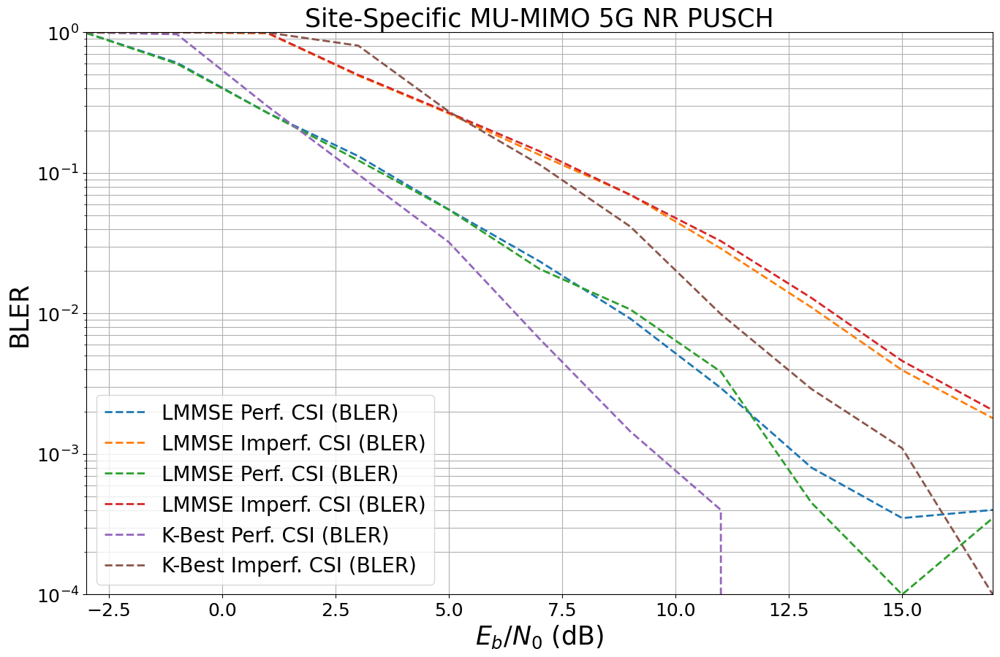

In [43]:
# and show figure
ber_plot(show_bler=True, show_ber=False, ylim=[1e-4,1], xlim=[-3,17])

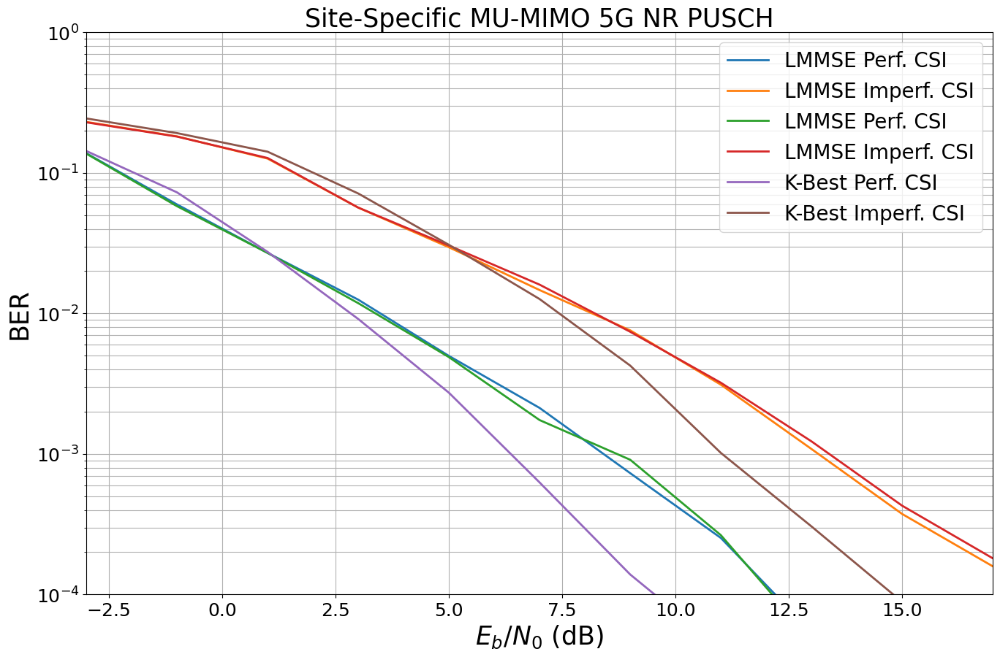

In [45]:
ber_plot(show_bler=False, show_ber=True, ylim=[1e-4,1], xlim=[-3,17])

SISO SETUP

In [44]:
# scene = load_scene(sionna.rt.scene.munich)
# scene.tx_array = PlanarArray(num_rows=1, num_cols=1, vertical_spacing=0.5, horizontal_spacing=0.5, pattern="tr38901", polarization="V")
# scene.rx_array = PlanarArray(num_rows=1, num_cols=1, vertical_spacing=0.5, horizontal_spacing=0.5, pattern="dipole", polarization="cross")
# tx = Transmitter(name="tx", position=[8.5, 21, 27])
# scene.add(tx)
# rx = Receiver(name="rx", position=[45, 90, 1.5], orientation=[0, 0, 0])
# scene.add(rx)
# tx.look_at(rx)  # Transmitter points towards receiver

# # Set scene frequency
# scene.frequency = 2.14e9  # in Hz

# # Compute propagation paths
# paths = scene.compute_paths(max_depth=5, num_samples=5e4)

# # Visualize paths in the scene
# scene.render(camera="scene-cam-0", paths=paths, show_devices=True, show_paths=True, resolution=[480, 320])

# model = Model(channel_model=channel_model, perfect_csi=False, detector=None, config=SISOConfig())
# model.run(batch_size=batch_size, ebno_db=2.)